In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

In [ ]:
# Load data
# df = yf.download(['KO', 'PEP'], start="2000-01-01", end="2020-01-01")
ticker1 = 'EWA'
ticker2 = 'EWC'
df = yf.download([ticker1, ticker2], start="2000-01-01", end="2020-01-01")
df.head()

/tmp/ipykernel_514/146048368.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download([ticker1, ticker2], start="2000-01-01", end="2020-01-01")
[*********************100%***********************]  2 of 2 completed


Price          Close                High                 Low            \
Ticker           EWA       EWC       EWA       EWC       EWA       EWC   
Date                                                                     
2000-01-03  3.643989  7.947598  3.747512  8.067111  3.643989  7.947598   
2000-01-04  3.561171  7.589059  3.581876  7.828084  3.499058  7.589059   
2000-01-05  3.581877  7.738450  3.581877  7.738450  3.499059  7.648815   
2000-01-06  3.540467  7.648814  3.540467  7.648814  3.478353  7.559179   
2000-01-07  3.519761  7.768329  3.561170  7.768329  3.519761  7.678694   

Price           Open           Volume         
Ticker           EWA       EWC    EWA    EWC  
Date                                          
2000-01-03  3.747512  8.067111   3800  11500  
2000-01-04  3.561171  7.828084   9700   8300  
2000-01-05  3.499059  7.648815   3600   6500  
2000-01-06  3.478353  7.559179   5800   3600  
2000-01-07  3.561170  7.678694  19300   8000

In [ ]:
df.dropna(inplace=True)
df.head()

Price          Close                High                 Low            \
Ticker           EWA       EWC       EWA       EWC       EWA       EWC   
Date                                                                     
2000-01-03  3.643989  7.947598  3.747512  8.067111  3.643989  7.947598   
2000-01-04  3.561171  7.589059  3.581876  7.828084  3.499058  7.589059   
2000-01-05  3.581877  7.738450  3.581877  7.738450  3.499059  7.648815   
2000-01-06  3.540467  7.648814  3.540467  7.648814  3.478353  7.559179   
2000-01-07  3.519761  7.768329  3.561170  7.768329  3.519761  7.678694   

Price           Open           Volume         
Ticker           EWA       EWC    EWA    EWC  
Date                                          
2000-01-03  3.747512  8.067111   3800  11500  
2000-01-04  3.561171  7.828084   9700   8300  
2000-01-05  3.499059  7.648815   3600   6500  
2000-01-06  3.478353  7.559179   5800   3600  
2000-01-07  3.561170  7.678694  19300   8000

In [ ]:
close = df['Close']
close.head()

Ticker,EWA,EWC
Date,,
2000-01-03,3.643989,7.947598
2000-01-04,3.561171,7.589059
2000-01-05,3.581877,7.738450
2000-01-06,3.540467,7.648814
2000-01-07,3.519761,7.768329


In [ ]:
norm1 = close[ticker1] / close[ticker1].iloc[0]
norm2 = close[ticker2] / close[ticker2].iloc[0]

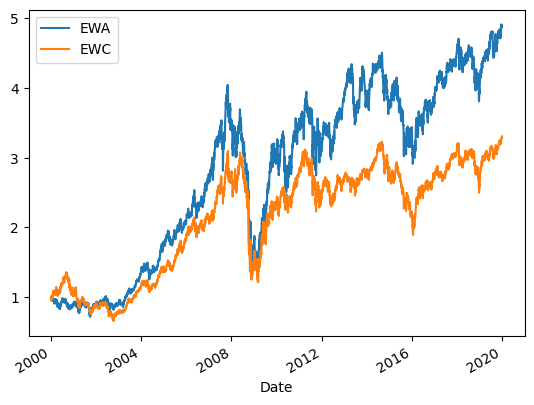

In [ ]:
norm1.plot()
norm2.plot();
plt.legend();

In [ ]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()

In [ ]:
X = np.log(close[ticker1].to_numpy())
X

array([1.29307905, 1.27008951, 1.27588696, ..., 2.88159794, 2.88027848,
       2.87675112])

In [ ]:
Y = np.log(close[ticker2].to_numpy())
Y

array([2.07286974, 2.02670759, 2.04620135, ..., 3.26553942, 3.26217909,
       3.26821937])

In [ ]:
X.shape, Y.shape

((5031,), (5031,))

In [ ]:
model.fit(X.reshape(-1, 1), Y)

LinearRegression()

In [ ]:
model.coef_

array([0.76361834])

In [ ]:
model.intercept_

np.float64(1.076116252218904)

In [ ]:
import statsmodels.api as sm

In [ ]:
smodel = sm.OLS(np.log(close[ticker2]), sm.add_constant(np.log(close[ticker1])))

In [ ]:
res = smodel.fit()

In [ ]:
res.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    EWC   R-squared:                       0.961
Model:                            OLS   Adj. R-squared:                  0.961
Method:                 Least Squares   F-statistic:                 1.242e+05
Date:                Mon, 27 Jul 2026   Prob (F-statistic):               0.00
Time:                        18:38:11   Log-Likelihood:                 5135.1
No. Observations:                5031   AIC:                        -1.027e+04
Df Residuals:                    5029   BIC:                        -1.025e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.0761      0.005    219.245      0.000       1.066       1.086
EWA            0.7636      0.002    352.440      0.000       0.759       0.768
==============================================================================
Omnibus:                      792.286   Durbin-Watson:                   0.015
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1881.713
Skew:                           0.896   Prob(JB):                         0.00
Kurtosis:                       5.401   Cond. No.                         10.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
residuals = Y - (model.intercept_ + model.coef_ * X)
residuals

array([ 0.00933461, -0.01927231, -0.00420558, ..., -0.01101787,
       -0.01337064, -0.00463681])

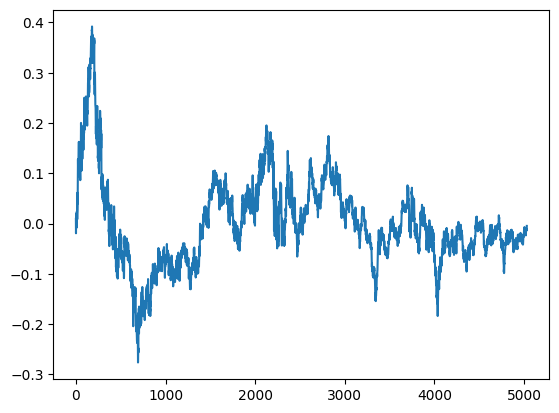

In [ ]:
plt.plot(residuals);

In [ ]:
from statsmodels.tsa.stattools import coint

In [ ]:
score, pvalue, _ = coint(np.log(close[ticker1]), np.log(close[ticker2]))
print(f"Cointegration p-value: {pvalue:.4f}")

Cointegration p-value: 0.1310


In [ ]:
spread = pd.Series(residuals)

In [ ]:
rolling_mean = spread.rolling(window=20).mean()
rolling_std = spread.rolling(window=20).std()

In [ ]:
z_score = (spread - rolling_mean) / rolling_std

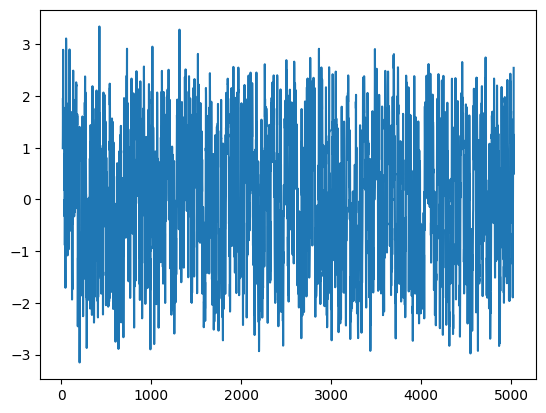

In [ ]:
plt.plot(z_score);

In [ ]:
z_score.max()

3.3440287953323633

In [ ]:
# -----------------------------------------
# 3. Trading loop
# -----------------------------------------

position = 0
#  1 = long spread
# -1 = short spread
#  0 = flat

positions = []
entries = []
exits = []

entry_threshold = 1.0
exit_threshold = 0.75

for i in range(len(df)):

    z = z_score[i]

    entry = 0
    exit_ = 0

    # ---------------------------------
    # ENTRY RULES
    # ---------------------------------

    if position == 0:

        # spread too low
        # expect spread to rise
        if z < -entry_threshold:

            # long spread:
            # long asset1
            # short asset2
            position = 1
            entry = 1

        # spread too high
        # expect spread to fall
        elif z > entry_threshold:

            # short spread:
            # short asset1
            # long asset2
            position = -1
            entry = -1

    # ---------------------------------
    # EXIT RULES
    # ---------------------------------

    elif position == 1:

        # exit when spread reverts
        if z > -exit_threshold:
            position = 0
            exit_ = 1

    elif position == -1:

        # exit when spread reverts
        if z < exit_threshold:
            position = 0
            exit_ = -1

    # store results
    positions.append(position)
    entries.append(entry)
    exits.append(exit_)

# -----------------------------------------
# 4. Attach to dataframe
# -----------------------------------------

df['position'] = positions
df['entry'] = entries
df['exit'] = exits

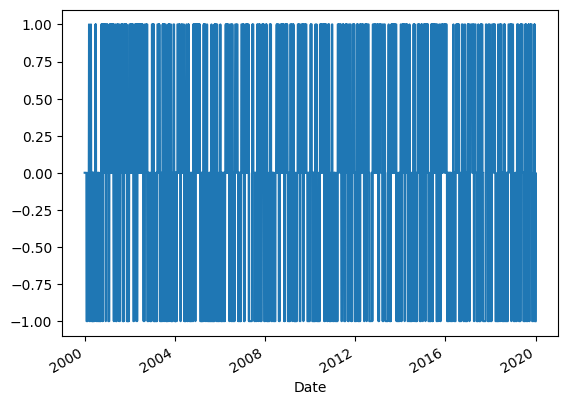

In [ ]:
df['position'].plot();

In [ ]:
df['Return1'] = close[ticker1].pct_change()
df['Return2'] = close[ticker2].pct_change()

In [ ]:
# spread_return = 0.5 * (df['Return2'] - df['Return1'])
gross = 1 + np.abs(model.coef_)
w1 = 1 / gross
w2 = model.coef_ / gross
spread_return = w1 * df['Return2'] - w2 * df['Return1']

In [ ]:
algo_returns = df['position'].shift(1) * spread_return

In [ ]:
# Compute cumulative return
cumulative_return = (1 + algo_returns).cumprod()
benchmark = (0.5 * (1 + df['Return1'] + 1 + df['Return2'])).cumprod()

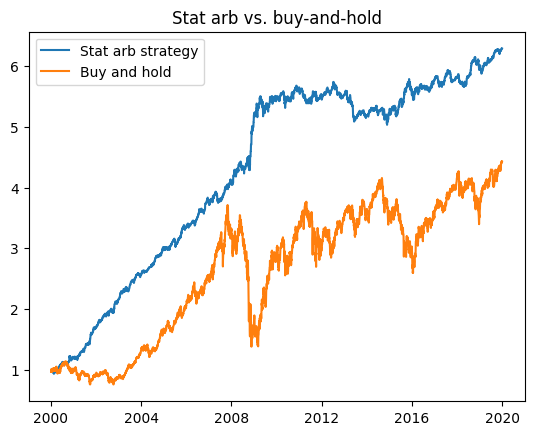

In [ ]:
# Plot cumulative return vs. buy-and-hold
plt.title("Stat arb vs. buy-and-hold")
plt.plot(cumulative_return, label='Stat arb strategy')
plt.plot(benchmark, label='Buy and hold')
plt.legend(loc='upper left');